# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 135.3 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <ArrowStringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


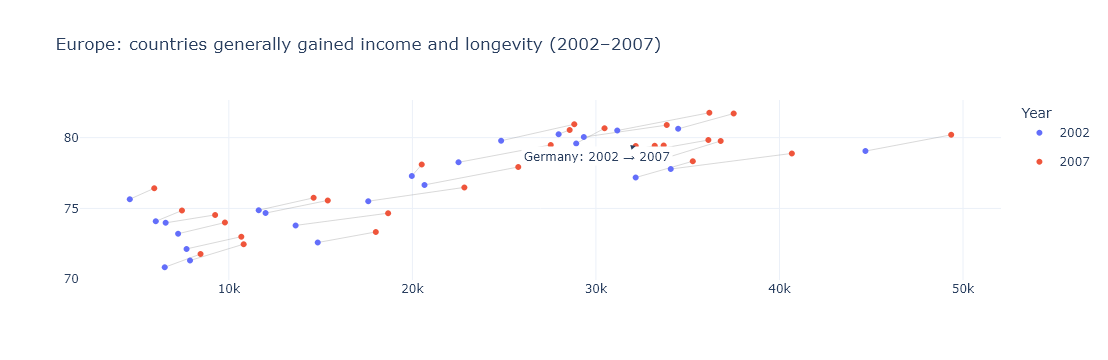

In [3]:
# Task 1
# YOUR CODE HERE
import plotly.express as px
import plotly.graph_objects as go

# Load the dataset here so this task works when run on its own.
df = px.data.gapminder()

continent = "Europe"
years = [2002, 2007]
task1_df = df.loc[
    (df["continent"] == continent) & df["year"].isin(years)
].copy()

task1_fig = go.Figure()
for _, country_data in task1_df.groupby("country"):
    country_data = country_data.sort_values("year")
    task1_fig.add_trace(
        go.Scatter(
            x=country_data["gdpPercap"],
            y=country_data["lifeExp"],
            mode="lines",
            line={"color": "rgba(120, 120, 120, 0.28)", "width": 1},
            showlegend=False,
            hoverinfo="skip",
        )
    )

points = px.scatter(
    task1_df,
    x="gdpPercap",
    y="lifeExp",
    color=task1_df["year"].astype(str),
    color_discrete_map={"2002": "#636EFA", "2007": "#EF553B"},
    hover_name="country",
    log_x=True,
    labels={
        "gdpPercap": "GDP per capita (US$, log scale)",
        "lifeExp": "Life expectancy (years)",
        "color": "Year",
    },
)
for trace in points.data:
    task1_fig.add_trace(trace)

germany = task1_df.loc[task1_df["country"] == "Germany"].sort_values("year")
if len(germany) == 2:
    task1_fig.add_annotation(
        x=germany.iloc[1]["gdpPercap"],
        y=germany.iloc[1]["lifeExp"],
        ax=germany.iloc[0]["gdpPercap"],
        ay=germany.iloc[0]["lifeExp"],
        xref="x",
        yref="y",
        axref="x",
        ayref="y",
        text="Germany: 2002 → 2007",
        showarrow=True,
        arrowhead=2,
        bgcolor="white",
    )

task1_fig.update_layout(
    title=f"{continent}: countries generally gained income and longevity (2002–2007)",
    legend_title_text="Year",
    template="plotly_white",
)
task1_fig.show()


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


In [7]:
import plotly.express as px

# Load the dataset here so this task works when run on its own.
df = px.data.gapminder()
highlight_continent = "Africa"
task2_df = df.loc[df["year"] == 2007].copy()
task2_df["highlight_group"] = task2_df["continent"].where(
    task2_df["continent"] == highlight_continent,
    "Other continents",
)

colors = {
    highlight_continent: "#E45756",
    "Other continents": "#B8BEC8",
}
task2_fig = px.scatter(
    task2_df,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    size_max=45,
    color="highlight_group",
    color_discrete_map=colors,
    hover_name="country",
    hover_data={"continent": True, "pop": ":,", "highlight_group": False},
    log_x=True,
    labels={
        "gdpPercap": "GDP per capita (US$, log scale)",
        "lifeExp": "Life expectancy (years)",
        "pop": "Population",
        "highlight_group": "Group",
    },
    title="In 2007, African countries clustered at lower incomes and life expectancy",
)

highlight_stats = task2_df.loc[
    task2_df["continent"] == highlight_continent,
    ["gdpPercap", "lifeExp"],
].median()
other_stats = task2_df.loc[
    task2_df["continent"] != highlight_continent,
    ["gdpPercap", "lifeExp"],
].median()
task2_fig.add_annotation(
    xref="paper",
    yref="paper",
    x=0.99,
    y=0.02,
    xanchor="right",
    yanchor="bottom",
    text=(
        f"{highlight_continent} median: ${highlight_stats['gdpPercap']:,.0f} GDP/person, "
        f"{highlight_stats['lifeExp']:.1f} years life expectancy<br>"
        f"Other continents: ${other_stats['gdpPercap']:,.0f}, "
        f"{other_stats['lifeExp']:.1f} years"
    ),
    showarrow=False,
    align="left",
    bgcolor="white",
    bordercolor="#B8BEC8",
    borderwidth=1,
)
task2_fig.update_layout(
    template="plotly_white",
    legend_title_text="Continent",
)
task2_fig.show()

NameError: name 'pio' is not defined